In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import os
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'
os.environ['TF_CUDNN_USE_AUTOTUNE'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'


I0000 00:00:1791877134.250407   59877 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791877137.139503   59877 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791877179.798141   59877 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
import os
path = "/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_datasetv2"
files = os.listdir(path)
train_path = os.path.join(path, "train set")
valid_path = os.path.join(path, "valid set")
test_path = os.path.join(path, "test set")
print("โฟลเดอร์ย่อยในพาธ:", files)

โฟลเดอร์ย่อยในพาธ: ['test set', 'train set', 'valid set']


In [3]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 50

print("จำนวนไฟล์และคลาสใน train set : ")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน valid set : ")
valid_dataset = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน test set : ")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

จำนวนไฟล์และคลาสใน train set : 
Found 2100 files belonging to 2 classes.


I0000 00:00:1791877224.818779   59877 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1791877224.825580   59877 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6




จำนวนไฟล์และคลาสใน valid set : 
Found 300 files belonging to 2 classes.


จำนวนไฟล์และคลาสใน test set : 
Found 600 files belonging to 2 classes.


คลาสทั้งหมดในชุดข้อมูล: ['safe', 'unsafe']


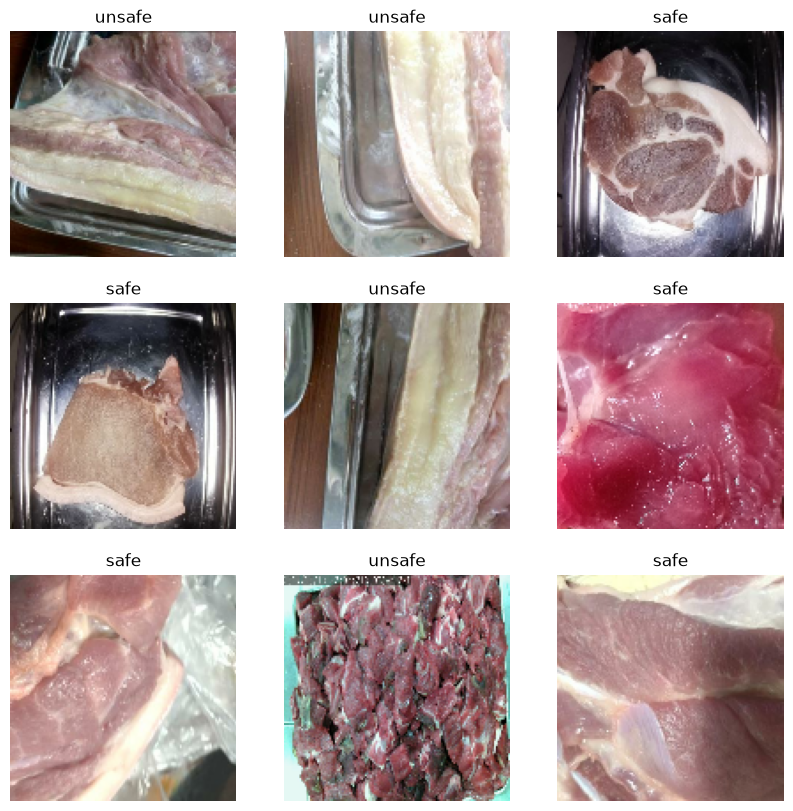

In [4]:
class_names = train_dataset.class_names
print("คลาสทั้งหมดในชุดข้อมูล:", class_names)
plt.figure(figsize=(10, 10)) 
for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [5]:
from tensorflow.keras.applications import InceptionV3
base_model = InceptionV3(input_shape=(IMAGE_SIZE[0],IMAGE_SIZE[1],3),include_top = False, weights = "imagenet")
base_model.summary()

Model: "inception_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 63, 63,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 63, 63,    │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 63, 63,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 61, 61,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 61, 61,    │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 61, 61,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 61, 61,    │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 61, 61,    │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 61, 61,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 30, 30,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 30, 30,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 30,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 30, 30,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 28, 28,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 28, 28,    │          0 │ batch_normalizat

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 21,768,352 (83.04 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [6]:
from tensorflow.keras.layers import Rescaling, GlobalAveragePooling2D, Dense, Input, BatchNormalization
from tensorflow.keras.models import Model

base_model.trainable = False

inputs = Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
custom_ann = Rescaling(1./255)(inputs)
custom_ann = base_model(custom_ann)

custom_ann = GlobalAveragePooling2D()(custom_ann)
custom_ann = tf.keras.layers.Dense(16, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(16, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(8, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = tf.keras.layers.Dense(4, activation='relu', kernel_initializer='random_normal')(custom_ann)
outputs = tf.keras.layers.Dense(units=1, activation='sigmoid')(custom_ann)

model = tf.keras.models.Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 2, 2, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        32,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_94          │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_95          │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,836,145 (83.30 MB)

 Trainable params: 33,297 (130.07 KB)

 Non-trainable params: 21,802,848 (83.17 MB)

In [7]:
from keras.callbacks import ModelCheckpoint
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='binary_crossentropy',metrics=['accuracy'])
checkpointer = ModelCheckpoint(filepath='model.weights.best.keras',verbose=0,save_best_only=True)
history = model.fit(train_dataset, validation_data=valid_dataset, epochs=100, callbacks=[checkpointer])

Epoch 1/100


/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791877240.626965   60362 service.cc:153] XLA service 0x247ad780 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791877240.627016   60362 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1791877241.107462   60362 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791877243.647756   60362 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1791877243.843464   60362 dot_merger.cc:481] Merging Dots in com

42/42 ━━━━━━━━━━━━━━━━━━━━ 73s 241ms/step - accuracy: 0.7410 - loss: 0.6693 - val_accuracy: 0.5600 - val_loss: 0.6842
Epoch 2/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.8957 - loss: 0.5394 - val_accuracy: 0.7533 - val_loss: 0.6128
Epoch 3/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.9319 - loss: 0.4059 - val_accuracy: 0.8400 - val_loss: 0.5214
Epoch 4/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.9495 - loss: 0.3062 - val_accuracy: 0.7933 - val_loss: 0.4927
Epoch 5/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.9652 - loss: 0.1828 - val_accuracy: 0.7967 - val_loss: 0.4401
Epoch 6/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.9710 - loss: 0.1092 - val_accuracy: 0.7533 - val_loss: 0.6059
Epoch 7/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.9719 - loss: 0.0857 - val_accuracy: 0.8167 - val_loss: 0.3713
Epoch 8/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.9829 - loss: 0.0557 - val_accuracy: 0.8167 - val

12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step


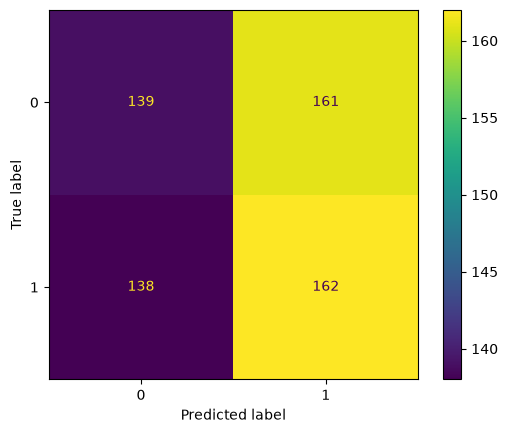

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(test_dataset)
y_pred = (y_pred > 0.5).astype("int32")

y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

cm = ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred))

cm.plot()
plt.show()

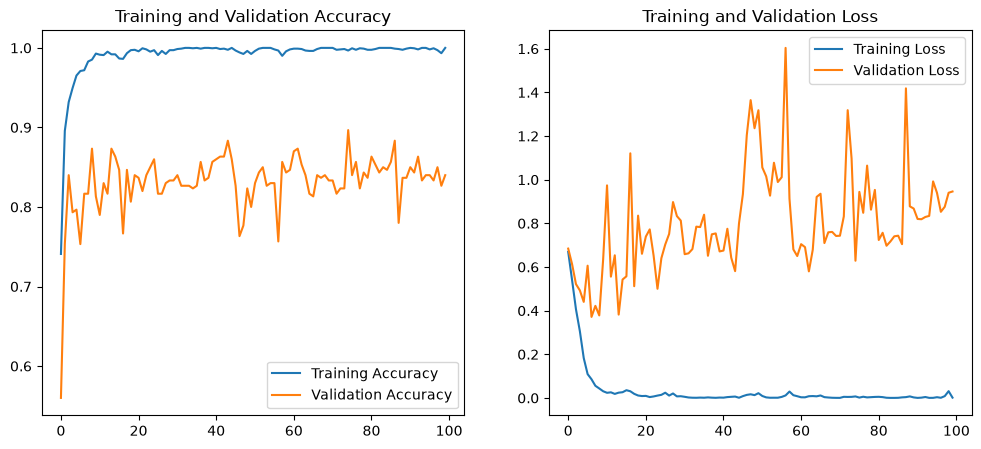

In [9]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# กราฟความแม่นยำ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# กราฟความสูญเสีย (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False
    
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='binary_crossentropy',metrics=['accuracy'])
history = model.fit(train_dataset, validation_data=valid_dataset, epochs=100, callbacks=[checkpointer])

Epoch 1/100


/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791877588.744585   60361 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_83631__.543


42/42 ━━━━━━━━━━━━━━━━━━━━ 107s 268ms/step - accuracy: 0.8776 - loss: 0.5769 - val_accuracy: 0.5533 - val_loss: 12.6462
Epoch 2/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.9748 - loss: 0.0711 - val_accuracy: 0.6200 - val_loss: 3.8256
Epoch 3/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 100ms/step - accuracy: 0.9933 - loss: 0.0200 - val_accuracy: 0.6733 - val_loss: 2.6280
Epoch 4/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.9905 - loss: 0.0457 - val_accuracy: 0.8567 - val_loss: 0.5340
Epoch 5/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 7s 172ms/step - accuracy: 0.9919 - loss: 0.0270 - val_accuracy: 0.8967 - val_loss: 0.3040
Epoch 6/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9938 - loss: 0.0163 - val_accuracy: 0.8867 - val_loss: 0.4894
Epoch 7/100
23/42 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.9957 - loss: 0.0097

12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 573ms/step


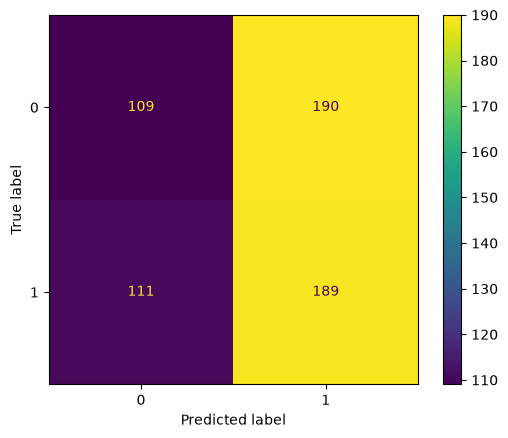

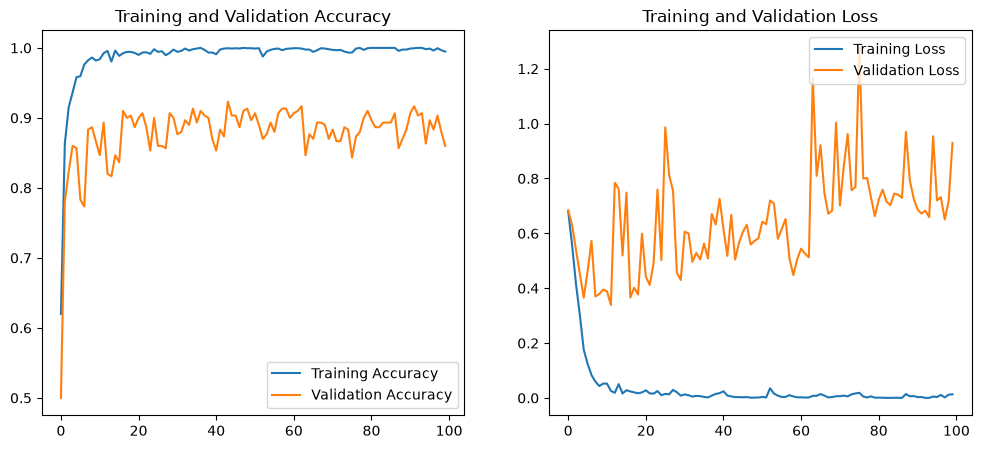

In [ ]:
y_pred = model.predict(test_dataset)
y_pred = (y_pred > 0.5).astype("int32")

y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

cm = ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred))

cm.plot()
plt.show()
plt.figure(figsize=(12, 5))

# กราฟความแม่นยำ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# กราฟความสูญเสีย (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
model.save('/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/model2_InceptionV3.h5')
print('saved model to drive')

saved model to drive


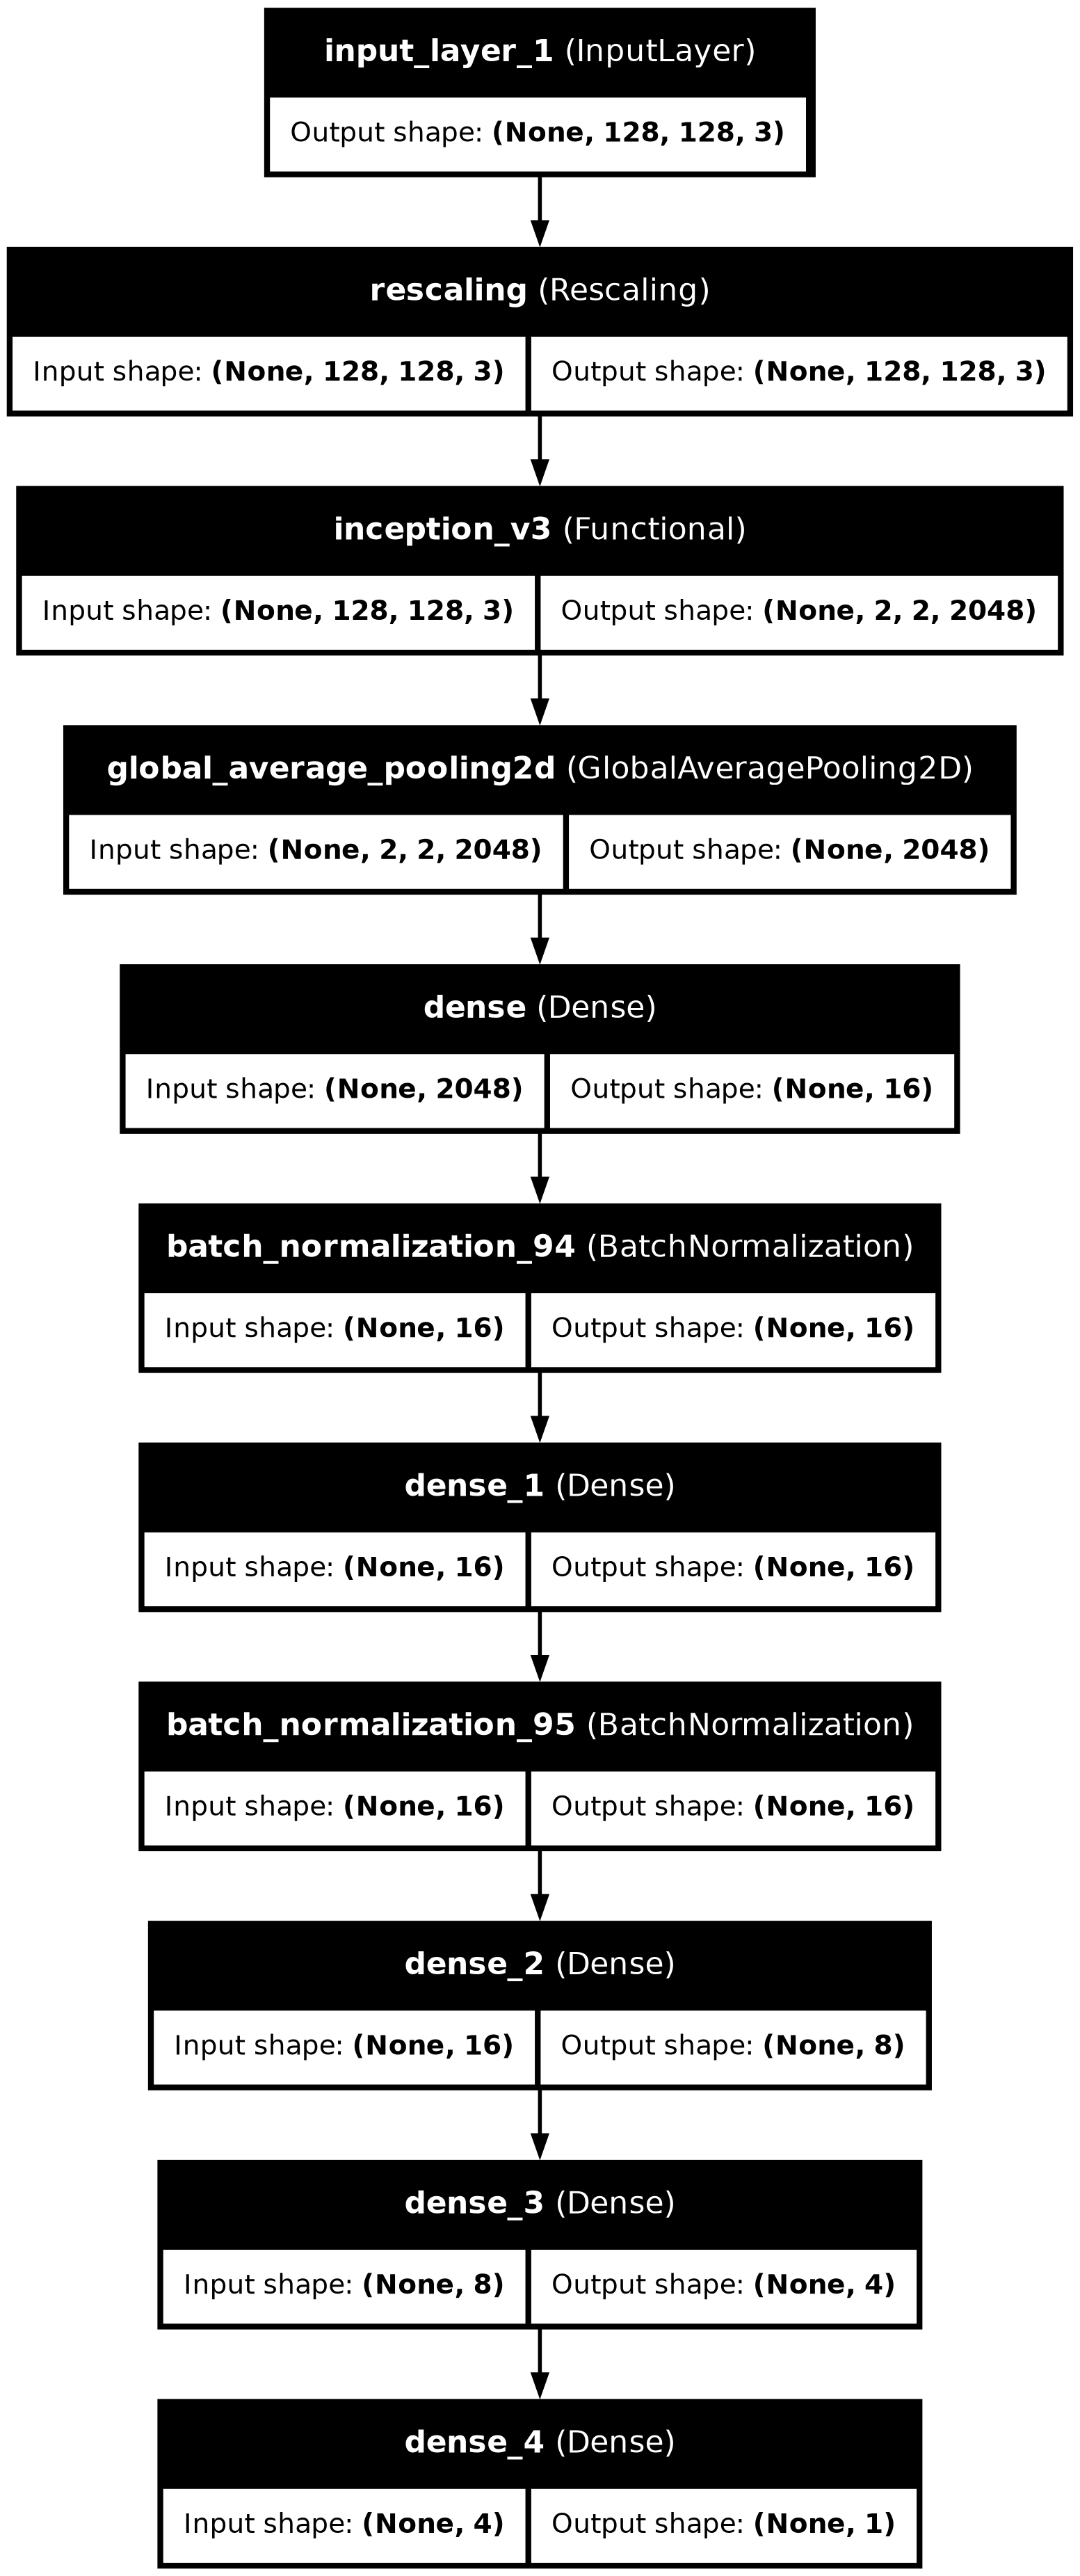

In [ ]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    show_shapes=True,
    show_layer_names=True
)

กำลังทำนายภาพทั้งหมด 10 ภาพ...
1/1 ━━━━━━━━━━━━━━━━━━━━ 32s 32s/step


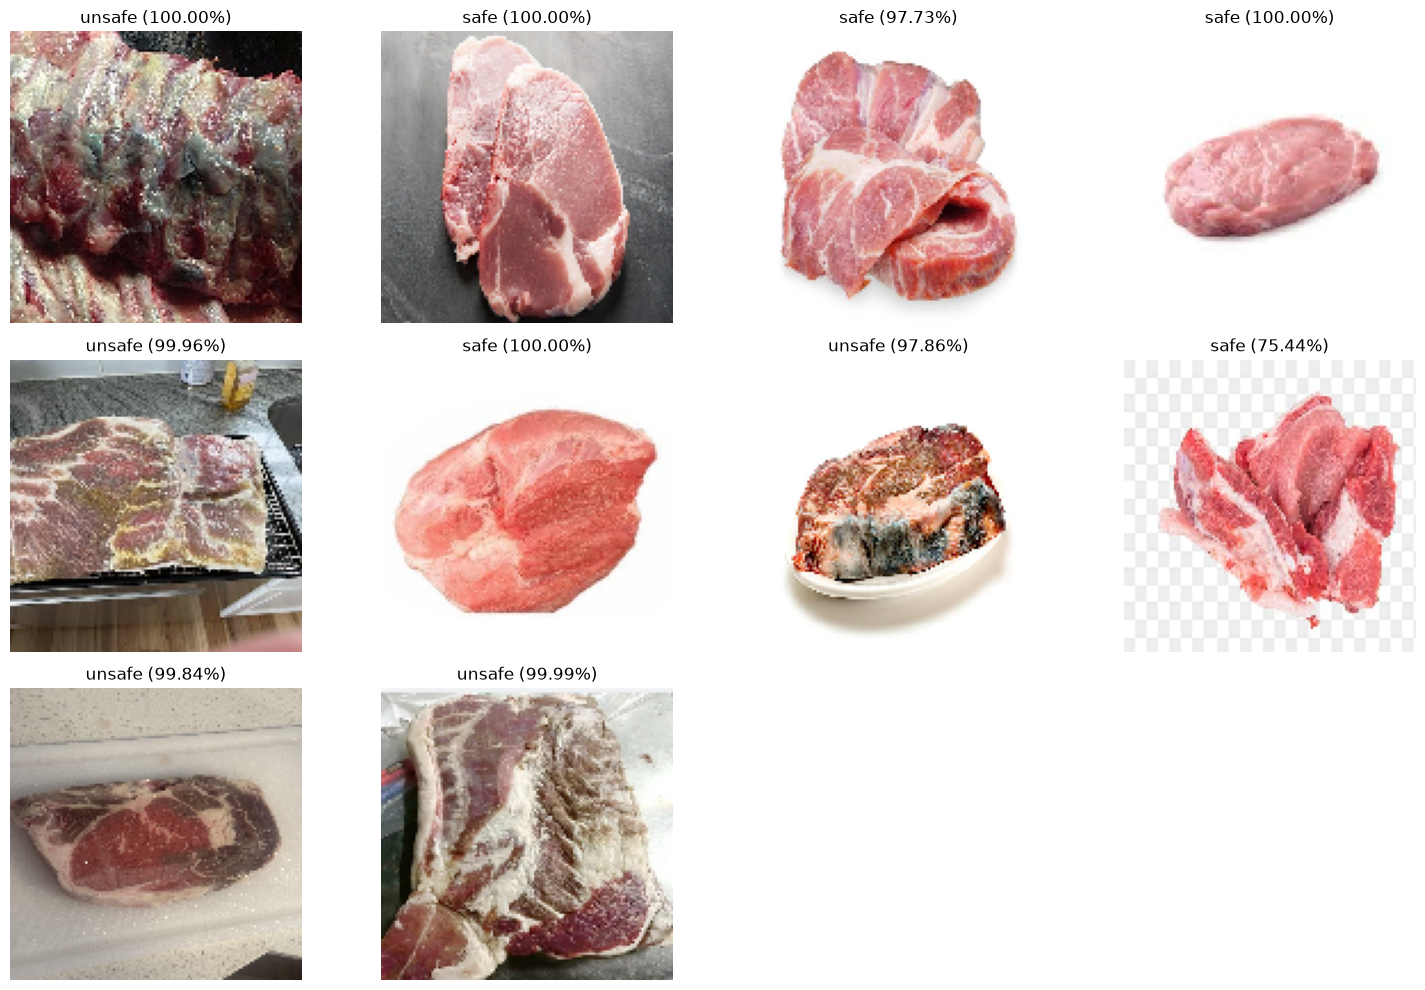

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1. กำหนดโฟลเดอร์ที่เก็บภาพใหม่ (เปลี่ยนชื่อโฟลเดอร์ได้ตามต้องการ)
unseen_dir = r"/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_dataset/unseen data"

# ดึงเฉพาะไฟล์รูปภาพมาเก็บไว้ในลิสต์
image_filenames = [f for f in os.listdir(unseen_dir) if f.endswith(('.png', '.jpg', '.jpeg'))]

IMAGE_SIZE = (128, 128)
class_names = ['safe', 'unsafe']  # อ้างอิงลำดับตามโฟลเดอร์ Train set

# 2. เตรียมข้อมูล: โหลดภาพและแปลงเป็นอาร์เรย์ (Array)
img_arrays = []
for filename in image_filenames:
    img_path = os.path.join(unseen_dir, filename)
    img = load_img(img_path, target_size=IMAGE_SIZE)
    img_array = img_to_array(img)
    img_arrays.append(img_array)

# นำภาพทั้งหมดมาต่อกันเป็น Batch รูปร่างจะเป็น (จำนวนภาพ, 256, 256, 3)
img_batch = np.array(img_arrays)

# 3. สั่งให้โมเดลทำนายผลรวดเดียวทุกภาพ
print(f"กำลังทำนายภาพทั้งหมด {len(image_filenames)} ภาพ...")
predictions = model.predict(img_batch)

# 4. พล็อตกราฟแสดงรูปภาพ คลาสที่ทำนายได้ และเปอร์เซ็นต์ความมั่นใจ
plt.figure(figsize=(15, 10))
for i in range(len(image_filenames)):
    # กำหนดให้แสดงผลแถวละ 4 ภาพ
    plt.subplot((len(image_filenames) // 4) + 1, 4, i + 1)
    
    # แสดงรูปภาพ (ต้องแปลงกลับเป็น uint8 เพื่อให้ภาพแสดงสีถูกต้อง)
    plt.imshow(img_arrays[i].astype("uint8"))
    
    # ดึงคะแนน (Score) จาก Sigmoid (0 ถึง 1)
    # ถ้าเกิน 0.5 แปลว่าโมเดลเอนเอียงไปทางคลาส 1 ('unsafe')
    score = predictions[i][0]
    if score > 0.5:
        predicted_class = class_names[1]
        confidence = score * 100
    else:
        predicted_class = class_names[0]
        confidence = (1 - score) * 100
        
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.axis("off")

plt.tight_layout()
plt.show()